# Random (Erdős–Rényi) network builder

This notebook shows how to use `get_network_random`, the builder that generates an
unstructured `Network` with the Erdős–Rényi model, draws it, and compares how traffic
spreads on it and on a scale-free network of the same size.

The topology comes from `networkx.erdos_renyi_graph` (Erdős and Rényi, *On Random
Graphs I*, 1959): each of the `n (n − 1) / 2` pairs of nodes is connected independently
with probability `p`. Degrees follow a binomial distribution with mean `p (n − 1)`, so,
unlike a scale-free network, there are no hubs.

The builder converts the graph into a `Network`, as `get_network_scale_free` does:

- every node `i` becomes a router `router_<i>`, with the attribute `degree`;
- every edge becomes a bidirectional link of class `router`;
- every router gets `hosts_per_router` hosts (`host_<i>_<h>`, with the attribute
  `router`), attached through links of class `host`. Hosts run the services, while
  routers forward the traffic.

All the router links share the same bandwidth and length (`bandwidth_mbps`,
`length_km`); host links use `host_bandwidth_mbps` and `host_length_km`.

## Setup

In [1]:
import json
import math
import os
import random
import shutil

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize

from eclypse.builders.network import get_network_random, get_network_scale_free
from eclypse.network import (
    NetworkApplication,
    PacketGenerationEvent,
    RoutingEvent,
    RoutingMetric,
)
from eclypse.placement.strategies import StaticStrategy
from eclypse.simulation import Simulation, SimulationConfig
from eclypse.utils.defaults import get_default_sim_path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Chart style: light surface, recessive axes and grid
SURFACE, TEXT, TEXT_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {"random": "#2a78d6", "scale-free": "#eb6834"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_MUTED,
    "axes.titlecolor": TEXT,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_MUTED,
    "ytick.color": TEXT_MUTED,
    "legend.frameon": False,
    "legend.labelcolor": TEXT,
    "font.size": 10,
})
RAMP = LinearSegmentedColormap.from_list(
    "blue_ramp", ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"]
)


def plain_graph(network, nodes):
    # Undirected networkx copy of part of a Network, used for layouts and drawing
    nodes = set(nodes)
    graph = nx.Graph()
    graph.add_nodes_from((n, dict(network.nodes[n])) for n in nodes)
    graph.add_edges_from(
        (u, v, dict(d)) for u, v, d in network.edges(data=True) if u in nodes and v in nodes
    )
    return graph

## 1. Build the network

300 routers with a mean degree of 8, i.e. `p = 8 / (n − 1)`, and one host per router.
The other parameters keep their defaults: 1 Gbps and 10 km for the router links,
100 Mbps and 1 km for the host links.

In [2]:
N = 300
MEAN_DEGREE = 8
P = MEAN_DEGREE / (N - 1)
net = get_network_random(N, P, hosts_per_router=1, seed=SEED)

degree = {r: net.nodes[r]["degree"] for r in net.routers}
degrees = np.array(list(degree.values()))
print(f"p = {P:.4f} (connectivity threshold ln(n)/n = {math.log(N) / N:.4f})")
print(f"{net.number_of_nodes()} nodes ({len(net.routers)} routers, {len(net.hosts)} hosts), "
      f"{net.number_of_edges() // 2} bidirectional links")
print("Connected:", nx.is_strongly_connected(net))
print(f"Router degree: min {degrees.min()}, median {np.median(degrees):.0f}, "
      f"mean {degrees.mean():.1f}, max {degrees.max()}")

p = 0.0268 (connectivity threshold ln(n)/n = 0.0190)
600 nodes (300 routers, 300 hosts), 1490 bidirectional links
Connected: True
Router degree: min 2, median 8, mean 7.9, max 21


## 2. Draw the network

The router graph with a force-directed layout (hosts are omitted: each router has one).
Size and color of a router grow with its degree: compared with a scale-free network,
the degrees stay close to the mean and there are no hubs.

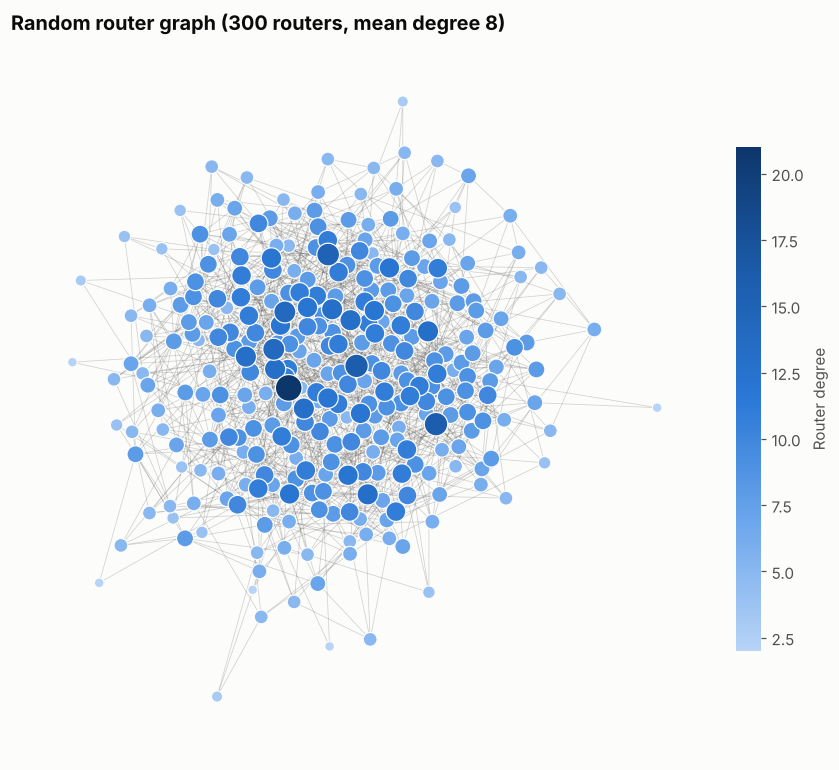

In [3]:
router_graph = plain_graph(net, net.routers)
layout = nx.spring_layout(router_graph, k=0.12, iterations=200, seed=SEED)
norm = Normalize(vmin=degrees.min(), vmax=degrees.max())

fig, ax = plt.subplots(figsize=(10, 8.5))
nx.draw_networkx_edges(router_graph, layout, ax=ax, width=0.5, edge_color=TEXT_MUTED, alpha=0.25)
order = sorted(router_graph.nodes, key=degree.get)
nx.draw_networkx_nodes(
    router_graph, layout, nodelist=order, ax=ax,
    node_size=[12 + 14 * degree[r] for r in order],
    node_color=[RAMP(norm(degree[r])) for r in order],
    edgecolors=SURFACE, linewidths=0.8,
)
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=RAMP), ax=ax, shrink=0.7, pad=0.02)
colorbar.set_label("Router degree", color=TEXT_MUTED)
colorbar.outline.set_visible(False)
ax.set_title(f"Random router graph ({N} routers, mean degree {MEAN_DEGREE})", loc="left")
ax.axis("off")
plt.show()

## 3. Degree distribution

The share of routers with each degree, against the binomial distribution
Bin(n − 1, p) of the model. Degrees concentrate around the mean, with no long tail.

Degree standard deviation: 2.64 (binomial 2.79)


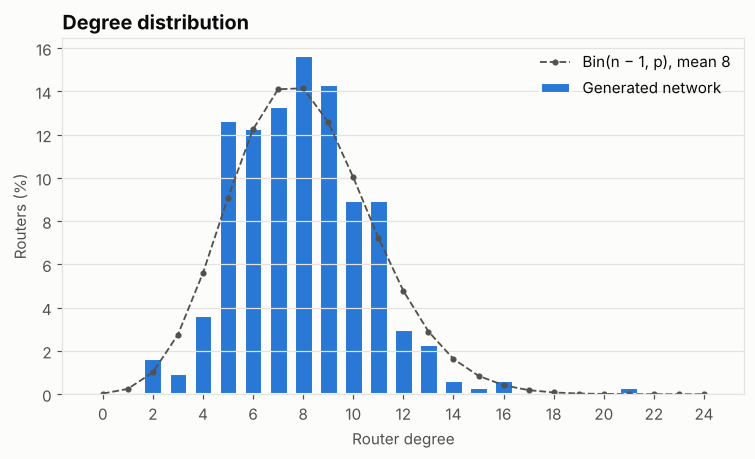

In [4]:
k = np.arange(0, degrees.max() + 4)
observed = np.array([(degrees == x).mean() for x in k])
expected = np.array([math.comb(N - 1, int(x)) * P**x * (1 - P) ** (N - 1 - x) for x in k])

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(k, 100 * observed, width=0.75, color=COLORS["random"], edgecolor=SURFACE, linewidth=2,
       label="Generated network")
ax.plot(k, 100 * expected, color=TEXT_MUTED, lw=1.2, ls="--", marker="o", markersize=3,
        label=f"Bin(n − 1, p), mean {P * (N - 1):.0f}")
ax.set_xlabel("Router degree")
ax.set_ylabel("Routers (%)")
ax.set_title("Degree distribution", loc="left")
ax.set_xticks(k[::2])
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
plt.show()

print(f"Degree standard deviation: {degrees.std():.2f} "
      f"(binomial {math.sqrt((N - 1) * P * (1 - P)):.2f})")

## 4. Connectivity

A random graph is not necessarily connected. For 300 routers and growing `p`, the
chart shows, over 30 graphs per value, the mean share of routers in the largest
connected component and the share of graphs that are connected. A giant component
appears when the mean degree exceeds 1 (`p = 1/n`), and the graph becomes connected
around `p = ln(n)/n`. Hosts on routers outside the largest component cannot reach the
others, and the packets sent to them are discarded.

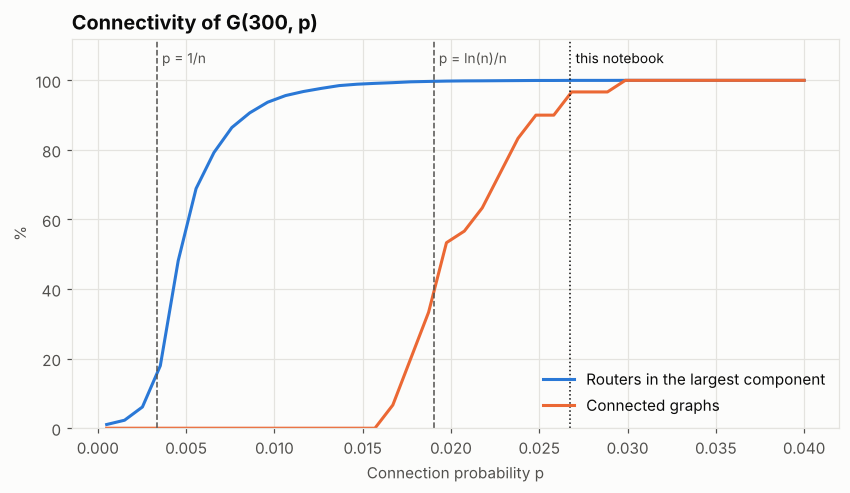

In [5]:
p_values = np.linspace(0.0005, 0.04, 40)
giant, connected = [], []
for p in p_values:
    sizes, conn = [], []
    for s in range(30):
        g = nx.erdos_renyi_graph(N, p, seed=s)
        largest = max(nx.connected_components(g), key=len)
        sizes.append(len(largest) / N)
        conn.append(len(largest) == N)
    giant.append(np.mean(sizes))
    connected.append(np.mean(conn))

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(p_values, 100 * np.array(giant), color=COLORS["random"], lw=2,
        label="Routers in the largest component")
ax.plot(p_values, 100 * np.array(connected), color=COLORS["scale-free"], lw=2,
        label="Connected graphs")
for x, label, color, style in ((1 / N, "p = 1/n", TEXT_MUTED, "--"),
                               (math.log(N) / N, "p = ln(n)/n", TEXT_MUTED, "--"),
                               (P, "this notebook", TEXT, ":")):
    ax.axvline(x, color=color, lw=1, ls=style)
    ax.text(x + 0.0003, 104, label, ha="left", va="bottom", color=color, fontsize=9)
ax.set_xlabel("Connection probability p")
ax.set_ylabel("%")
ax.set_ylim(0, 112)
ax.set_title(f"Connectivity of G({N}, p)", loc="left")
ax.legend(loc="lower right")
plt.show()

## 5. Simulate traffic

The same traffic on the random network and on a scale-free network with the same
number of routers and the same mean degree (`get_network_scale_free` with `m = 4`):
one service per host and 100 random flows between them, each with 2 packets of 1500
bytes per step on average, for 60 steps of 1 ms. The results are written to
`~/eclypse-sim/demo_random_builder/random` and
`~/eclypse-sim/demo_random_builder/scale_free`.

In [6]:
def simulate(network, results):
    app = NetworkApplication(f"App_{network.id}")
    mapping = {}
    for host in network.hosts:
        app.add_node(f"svc_{host}", cpu=1, ram=1)
        mapping[f"svc_{host}"] = host
    flow_rng = random.Random(SEED)
    while app.number_of_edges() < 100:
        src, dst = flow_rng.sample(network.hosts, 2)
        if not app.has_edge(f"svc_{src}", f"svc_{dst}"):
            app.add_edge(f"svc_{src}", f"svc_{dst}", packet_size_bytes=1500, avg_packets_per_step=2.0)

    # ECLYPSE writes to a new timestamped folder if the path exists: start from a clean one
    shutil.rmtree(results, ignore_errors=True)
    config = SimulationConfig(
        seed=SEED,
        max_steps=60,
        path=results,
        events=[PacketGenerationEvent(), RoutingEvent(step_duration_s=0.001), RoutingMetric()],
        include_default_metrics=False,
        report_format="json",
        report_backend="pandas",
        log_level="ERROR",
        remote=False,
    )
    sim = Simulation(network, simulation_config=config)
    sim.register(app, placement_strategy=StaticStrategy(mapping))
    sim.start()
    sim.wait()

    frames = []
    with open(os.path.join(results, "json", "application.jsonl")) as file:
        for line in file:
            record = json.loads(line)
            if record.get("callback_name") != "traffic_routing":
                continue
            columns = {name: values for _, name, values in (m for m in record["data"] if len(m) == 3)}
            if columns:
                frames.append(pd.DataFrame(columns))
    hops = pd.concat(frames, ignore_index=True)
    hops["link_class"] = [network.edges[tuple(hop.split("->"))]["link_class"] for hop in hops["hop"]]
    hops["sender"] = hops["hop"].str.split("->").str[0]
    print(f"{network.id:>14}: {len(hops)} hops, {hops['packet_id'].nunique()} packets, "
          f"{network.dropped_packets} dropped")
    return hops


RESULTS = get_default_sim_path() / "demo_random_builder"
scale_free = get_network_scale_free(N, MEAN_DEGREE // 2, hosts_per_router=1, seed=SEED)
results = {
    "random": (net, simulate(net, RESULTS / "random")),
    "scale-free": (scale_free, simulate(scale_free, RESULTS / "scale_free")),
}

    random_net: 55455 hops, 11774 packets, 0 dropped
scale_free_net: 55858 hops, 11848 packets, 0 dropped


## 6. Where the traffic goes

Each router transmission is a packet sent by a router to another router. For each
network, the routers are sorted from the highest to the lowest degree, and the curve
shows the cumulative share of the transmissions they make; the dashed line is what an
even split would give. In the random network the busiest routers carry a much smaller
share than the hubs of the scale-free one.

Share of the router transmissions made by the routers with the highest degree (%):
            top 5%  top 10%  top 20%
random           9       14       29
scale-free      46       59       65


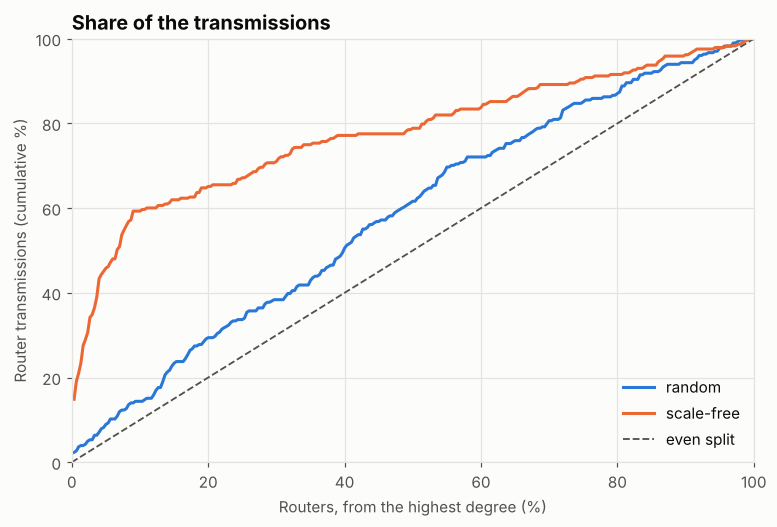

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
summary = {}
for name, (network, hops) in results.items():
    deg = {r: network.nodes[r]["degree"] for r in network.routers}
    sent = (hops.loc[hops["link_class"] == "router", "sender"].value_counts()
            .reindex(network.routers, fill_value=0))
    ordered = sent.loc[sorted(network.routers, key=lambda r: (-deg[r], r))]
    share = ordered.cumsum().to_numpy() / ordered.sum()
    rank = np.arange(1, len(share) + 1) / len(share)
    ax.plot(100 * rank, 100 * share, color=COLORS[name], lw=2, label=name)
    summary[name] = {f"top {pct}%": round(100 * share[int(len(share) * pct / 100) - 1])
                     for pct in (5, 10, 20)}
ax.plot([0, 100], [0, 100], color=TEXT_MUTED, lw=1.2, ls="--", label="even split")
ax.set_xlabel("Routers, from the highest degree (%)")
ax.set_ylabel("Router transmissions (cumulative %)")
ax.set_title("Share of the transmissions", loc="left")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.legend(loc="lower right")
plt.show()

print("Share of the router transmissions made by the routers with the highest degree (%):")
print(pd.DataFrame(summary).T.to_string())

## 7. Path lengths and delays

The number of hops of the delivered packets, including the two host links, in the two
networks. With the same mean degree the two networks have almost the same path
lengths: short paths do not need hubs, but in the scale-free network they go through
the hubs, which is why the hubs carry most of the traffic.

    random: mean path length 4.88 hops
scale-free: mean path length 4.87 hops

Mean hop delay by link class in the random network (ms):
            processing_ms  queue_ms  transmission_ms  propagation_ms
link_class                                                          
router                0.1     0.013            0.012           0.050
host                  0.1     0.167            0.120           0.005


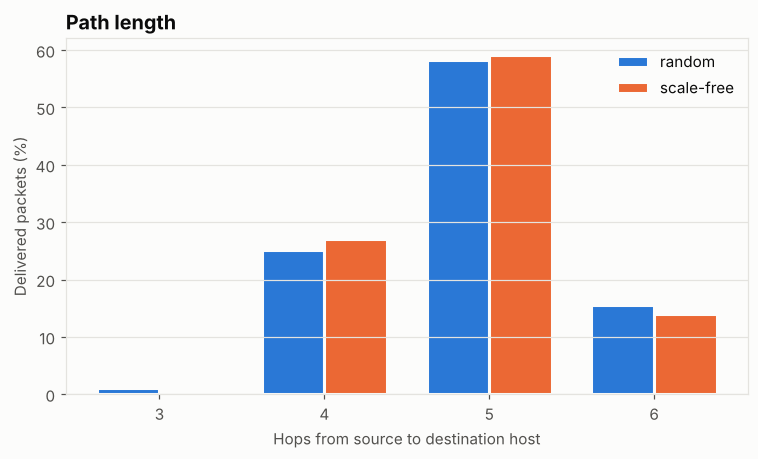

In [8]:
lengths = {}
for name, (network, hops) in results.items():
    last = hops.sort_values("hop_count").groupby("packet_id").tail(1)
    delivered = last[(last["link_class"] == "host") & last["hop"].str.startswith("router_") & ~last["dropped"]]
    lengths[name] = delivered["hop_count"].value_counts(normalize=True).sort_index()
lengths = pd.DataFrame(lengths).fillna(0.0)

fig, ax = plt.subplots(figsize=(8, 4.2))
width = 0.38
for i, name in enumerate(lengths.columns):
    ax.bar(lengths.index + (i - 0.5) * width, 100 * lengths[name], width=width, color=COLORS[name],
           edgecolor=SURFACE, linewidth=2, label=name)
ax.set_xlabel("Hops from source to destination host")
ax.set_ylabel("Delivered packets (%)")
ax.set_title("Path length", loc="left")
ax.set_xticks(lengths.index)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
plt.show()

for name, dist in lengths.items():
    print(f"{name:>10}: mean path length {np.average(dist.index, weights=dist):.2f} hops")

components = ["processing_ms", "queue_ms", "transmission_ms", "propagation_ms"]
hops = results["random"][1]
print("\nMean hop delay by link class in the random network (ms):")
print(hops[~hops["dropped"]].groupby("link_class")[components].mean().reindex(["router", "host"]).round(3).to_string())

## Notes

- **Disconnected graphs.** Below `p = ln(n)/n` the generated network is likely to be
  disconnected (check it with `networkx.is_strongly_connected`). Packets towards hosts
  that cannot be reached are discarded with a warning.
- **Equal-cost paths.** All the router links have the same bandwidth, hence the same
  routing cost: routes follow the minimum number of hops, and many pairs of routers
  have several shortest paths. Which one is used depends on the library that computes
  the shortest paths, so the load of single links may differ between machines, while
  the overall picture does not.
- **Seed.** The same `seed` gives the same graph, so experiments can be repeated on
  the same topology.